In [ ]:
#Import the dataset and explore basic info
1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/Titanic-Dataset.csv")
print("Shape:", df.shape)
df.head()

Matplotlib is building the font cache; this may take a moment.


Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.info()



<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
print(df.isnull().sum())
print("\nMissing %:")
print((df.isnull().mean() * 100).round(1))


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Missing %:
PassengerId     0.0
Survived        0.0
Pclass          0.0
Name            0.0
Sex             0.0
Age            19.9
SibSp           0.0
Parch           0.0
Ticket          0.0
Fare            0.0
Cabin          77.1
Embarked        0.2
dtype: float64


In [7]:
df.describe()



,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [9]:
print(df["Survived"].value_counts())
print(df["Survived"].value_counts(normalize=True).round(2))


Survived
0    549
1    342
Name: count, dtype: int64
Survived
0    0.62
1    0.38
Name: proportion, dtype: float64


In [ ]:

# Handling Missing Values

df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df = df.drop(columns=["Cabin"])

print(df.isnull().sum())



In [13]:
# Drop useless columns and encode categorical features

df = df.drop(columns=["PassengerId", "Name", "Ticket"])

df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
df = pd.get_dummies(df, columns=["Embarked"], drop_first=True, dtype=int)

df.head()



,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,1
1,1,1,1,38.0,1,0,71.2833,0,0
2,1,3,1,26.0,0,0,7.9250,0,1
3,1,1,1,35.0,1,0,53.1000,0,1
4,0,3,0,35.0,0,0,8.0500,0,1


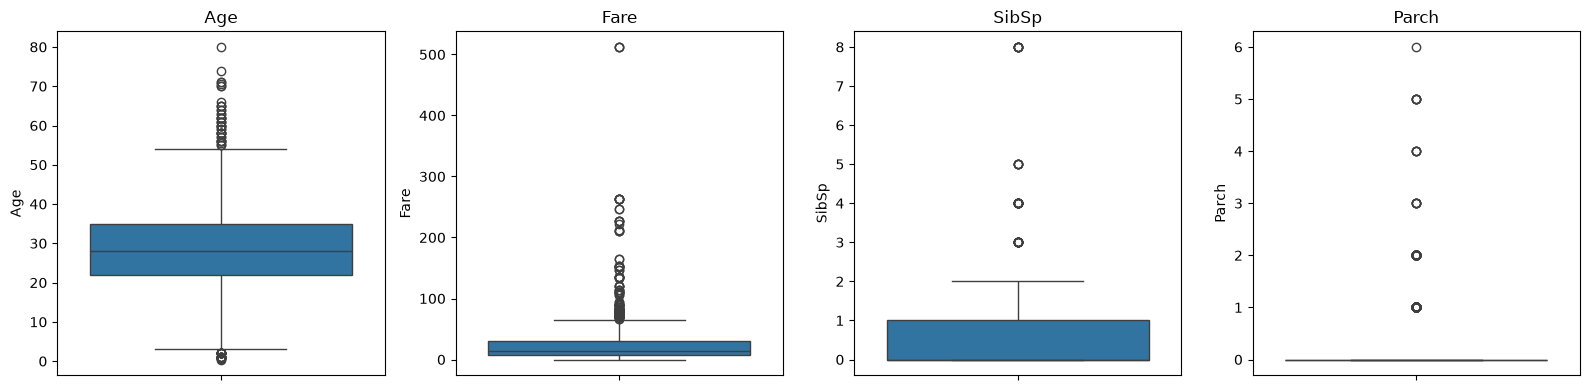

In [14]:
# Visualize outliers with boxplots

num_cols = ["Age", "Fare", "SibSp", "Parch"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig("images/boxplots_before.png", dpi=150)
plt.show()




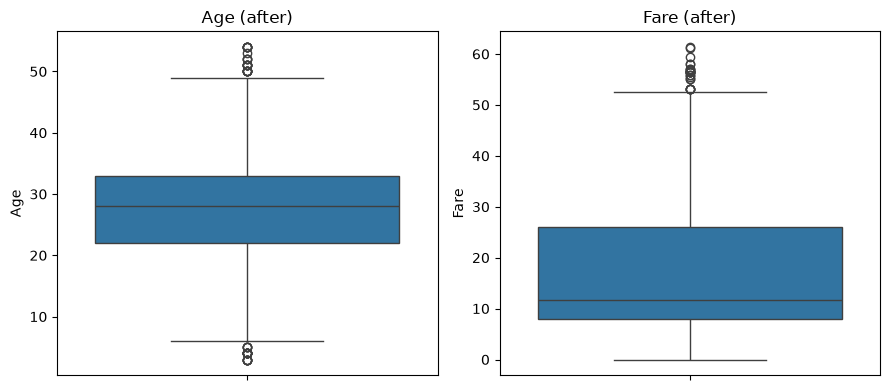

In [ ]:
# Remove outliers using the IQR method

def remove_outliers_iqr(data, columns):
    for col in columns:
        q1, q3 = data[col].quantile(0.25), data[col].quantile(0.75)
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        before = len(data)
        data = data[(data[col] >= lower) & (data[col] <= upper)]
        print(f"{col}: removed {before - len(data)} rows")
    return data

df_clean = remove_outliers_iqr(df, ["Age", "Fare"])
print("Rows before:", len(df), "| after:", len(df_clean))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, col in zip(axes, ["Age", "Fare"]):
    sns.boxplot(y=df_clean[col], ax=ax)
    ax.set_title(f"{col} (after)")
plt.tight_layout()
plt.savefig("images/boxplots_after.png", dpi=150)
plt.show()



In [17]:
# Normalize / standardize numerical features

from sklearn.preprocessing import StandardScaler, MinMaxScaler

scale_cols = ["Age", "Fare", "SibSp", "Parch"]

df_std = df_clean.copy()
df_std[scale_cols] = StandardScaler().fit_transform(df_std[scale_cols])

df_norm = df_clean.copy()
df_norm[scale_cols] = MinMaxScaler().fit_transform(df_norm[scale_cols])

print("Standardized:")
print(df_std[scale_cols].describe().loc[["mean", "std"]].round(2))
print("\nNormalized:")
print(df_norm[scale_cols].describe().loc[["min", "max"]].round(2))


Standardized:
      Age  Fare  SibSp  Parch
mean  0.0  -0.0   -0.0    0.0
std   1.0   1.0    1.0    1.0

Normalized:
     Age  Fare  SibSp  Parch
min  0.0   0.0    0.0    0.0
max  1.0   1.0    1.0    1.0


In [18]:
# Save the cleaned datasets

df_clean.to_csv("data/titanic_cleaned.csv", index=False)
df_std.to_csv("data/titanic_cleaned_standardized.csv", index=False)
print("Saved!")


Saved!
